In [62]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler, OrdinalEncoder
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [64]:
filepath='/content/drive/MyDrive/AI ML-Course/AI ML-Dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv'
tel_df=pd.read_csv(filepath)

###Data Preprocessing

In [65]:
tel_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [66]:
tel_df['TotalCharges'].nunique()

6531

In [67]:
tel_df['TotalCharges']=pd.to_numeric(tel_df['TotalCharges'],errors='coerce')

In [68]:
tel_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [69]:
tel_df['TotalCharges'].isna().sum()

np.int64(11)

In [70]:
tel_df.shape

(7043, 21)

In [71]:
tel_df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [72]:
tel_df.duplicated().sum()

np.int64(0)

In [73]:
(tel_df.isna().sum()/len(tel_df))*100

,0
customerID,0.000000
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000


In [74]:
tel_df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [75]:
tel_df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


###Train-test-split

In [76]:
X=tel_df.drop(columns=['Churn','customerID'])
y=tel_df['Churn']

In [77]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

##convert num_col and cat_col

In [78]:
num_col = X_train.select_dtypes(include='number').columns.drop('SeniorCitizen')
cat_col=X_train.select_dtypes(include='object').columns

##Numerical Preprocessing

In [79]:
num_col

Index(['tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [80]:
cat_col

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [81]:
X_train[num_col].isna().sum()

,0
tenure,0
MonthlyCharges,0
TotalCharges,8


In [82]:
median = X_train['TotalCharges'].median()

X_train['TotalCharges'] = X_train['TotalCharges'].fillna(median)
X_test['TotalCharges'] = X_test['TotalCharges'].fillna(median)

In [83]:
X_train[num_col].isna().sum()

,0
tenure,0
MonthlyCharges,0
TotalCharges,0


###Scaling numeric column

In [84]:
scaler=StandardScaler().set_output(transform='pandas')
X_train_num_scaled=scaler.fit_transform(X_train[num_col])
X_test_num_scaled=scaler.transform(X_test[num_col])

In [85]:
X_train_num_final=pd.concat([X_train['SeniorCitizen'],X_train_num_scaled],axis=1)
X_test_num_final=pd.concat([X_test['SeniorCitizen'],X_test_num_scaled],axis=1)

In [86]:
X_train_num_scaled

,tenure,MonthlyCharges,TotalCharges
3738,0.102371,-0.521976,-0.263290
3151,-0.711743,0.337478,-0.504815
4860,-0.793155,-0.809013,-0.751214
3867,-0.263980,0.284384,-0.173700
3810,-1.281624,-0.676279,-0.990851
...,...,...,...
6303,1.567778,1.470695,2.373711
6227,-1.240918,-0.626504,-0.975133
4673,-0.304686,1.256662,0.157569
2710,-0.345392,-1.477661,-0.798435


##Categorical Preprocessing

In [87]:
for col in cat_col:
  print(f'{col} ==> {X_train[col].unique()}')

gender ==> ['Male' 'Female']
Partner ==> ['No' 'Yes']
Dependents ==> ['No' 'Yes']
PhoneService ==> ['No' 'Yes']
MultipleLines ==> ['No phone service' 'No' 'Yes']
InternetService ==> ['DSL' 'Fiber optic' 'No']
OnlineSecurity ==> ['No' 'Yes' 'No internet service']
OnlineBackup ==> ['No' 'Yes' 'No internet service']
DeviceProtection ==> ['Yes' 'No' 'No internet service']
TechSupport ==> ['No' 'Yes' 'No internet service']
StreamingTV ==> ['Yes' 'No' 'No internet service']
StreamingMovies ==> ['Yes' 'No' 'No internet service']
Contract ==> ['Month-to-month' 'Two year' 'One year']
PaperlessBilling ==> ['No' 'Yes']
PaymentMethod ==> ['Electronic check' 'Mailed check' 'Credit card (automatic)'
 'Bank transfer (automatic)']


In [88]:
binary_col=['Partner','Dependents','PhoneService','PaperlessBilling']
for col in binary_col:
  X_train[col]=X_train[col].map({'No':0,'Yes':1})
  X_test[col]=X_test[col].map({'No':0,'Yes':1})

X_train['gender']=X_train['gender'].map({'Male':0,'Female':1})
X_test['gender']=X_test['gender'].map({'Male':0,'Female':1})

In [89]:
X_train[binary_col]

,Partner,Dependents,PhoneService,PaperlessBilling
3738,0,0,0,0
3151,1,1,1,0
4860,1,1,0,0
3867,1,0,1,1
3810,1,1,1,0
...,...,...,...,...
6303,1,0,1,0
6227,0,0,1,0
4673,0,0,1,1
2710,1,0,1,0


In [90]:
X_train[cat_col]

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
3738,0,0,0,0,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,0,Electronic check
3151,0,1,1,1,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,0,Mailed check
4860,0,1,1,0,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,0,Mailed check
3867,1,1,0,1,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,1,Credit card (automatic)
3810,0,1,1,1,No,DSL,No,No,No,No,No,No,Month-to-month,0,Electronic check
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6303,1,1,0,1,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Two year,0,Electronic check
6227,0,0,0,1,No,DSL,No,No,No,No,No,No,Month-to-month,0,Bank transfer (automatic)
4673,1,0,0,1,Yes,Fiber optic,Yes,Yes,No,No,Yes,Yes,Month-to-month,1,Mailed check
2710,1,1,0,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,0,Credit card (automatic)


In [91]:
X_train[cat_col].isna().sum()

,0
gender,0
Partner,0
Dependents,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0
DeviceProtection,0
TechSupport,0


##onehotencoding

In [92]:
ohe=OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_col=[col for col in cat_col if col not in ['gender']+binary_col]
ohe_col

['MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaymentMethod']

In [93]:
X_train_cat_ohe=pd.DataFrame(
    ohe.fit_transform(X_train[ohe_col]),
    columns=ohe.get_feature_names_out(ohe_col),
    index=X_train.index
)
X_test_cat_ohe=pd.DataFrame(
    ohe.transform(X_test[ohe_col]),
    columns=ohe.get_feature_names_out(ohe_col),
    index=X_test.index
)

In [94]:
X_train_cat_ohe

,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3867,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6303,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6227,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4673,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2710,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [95]:
X_test_cat_ohe

,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
437,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2280,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2235,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4460,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3761,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5143,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4439,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3857,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4758,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [96]:
X_train_cat_final=pd.concat([X_train['gender'],X_train[binary_col],X_train_cat_ohe],axis=1)
X_test_cat_final=pd.concat([X_test['gender'],X_test[binary_col],X_test_cat_ohe],axis=1)

In [97]:
X_train_cat_final

,gender,Partner,Dependents,PhoneService,PaperlessBilling,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,0,0,0,0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,0,1,1,1,0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,0,1,1,0,0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3867,1,1,0,1,1,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,0,1,1,1,0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6303,1,1,0,1,0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6227,0,0,0,1,0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4673,1,0,0,1,1,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2710,1,1,0,1,0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


##Concat numerical and categorical columns

In [98]:
X_train_final=pd.concat([X_train_num_final,X_train_cat_final],axis=1)
X_test_final=pd.concat([X_test_num_final,X_test_cat_final],axis=1)

In [99]:
X_train_final

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender,Partner,Dependents,PhoneService,PaperlessBilling,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,0.102371,-0.521976,-0.263290,0,0,0,0,0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,0,-0.711743,0.337478,-0.504815,0,1,1,1,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,0,-0.793155,-0.809013,-0.751214,0,1,1,0,0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3867,0,-0.263980,0.284384,-0.173700,1,1,0,1,1,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,0,-1.281624,-0.676279,-0.990851,0,1,1,1,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6303,0,1.567778,1.470695,2.373711,1,1,0,1,0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6227,0,-1.240918,-0.626504,-0.975133,0,0,0,1,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4673,1,-0.304686,1.256662,0.157569,1,0,0,1,1,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2710,0,-0.345392,-1.477661,-0.798435,1,1,0,1,0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [100]:
X_train_final.isna().sum()

,0
SeniorCitizen,0
tenure,0
MonthlyCharges,0
TotalCharges,0
gender,0
Partner,0
Dependents,0
PhoneService,0
PaperlessBilling,0
MultipleLines_No,0


##Traget encoding

In [101]:
y_train=y_train.map({'No':0,'Yes':1})
y_test=y_test.map({'No':0,'Yes':1})

In [102]:
y_train.value_counts()

,count
Churn,
0,4139
1,1495


###Class imbalance handling

In [103]:
smote=SMOTE(random_state=42)
X_train_balance,y_train_balance=smote.fit_resample(X_train_final,y_train)
y_train_balance.value_counts()

,count
Churn,
0,4139
1,4139


##Correleation Heatmap

<Figure size 1200x1600 with 0 Axes>

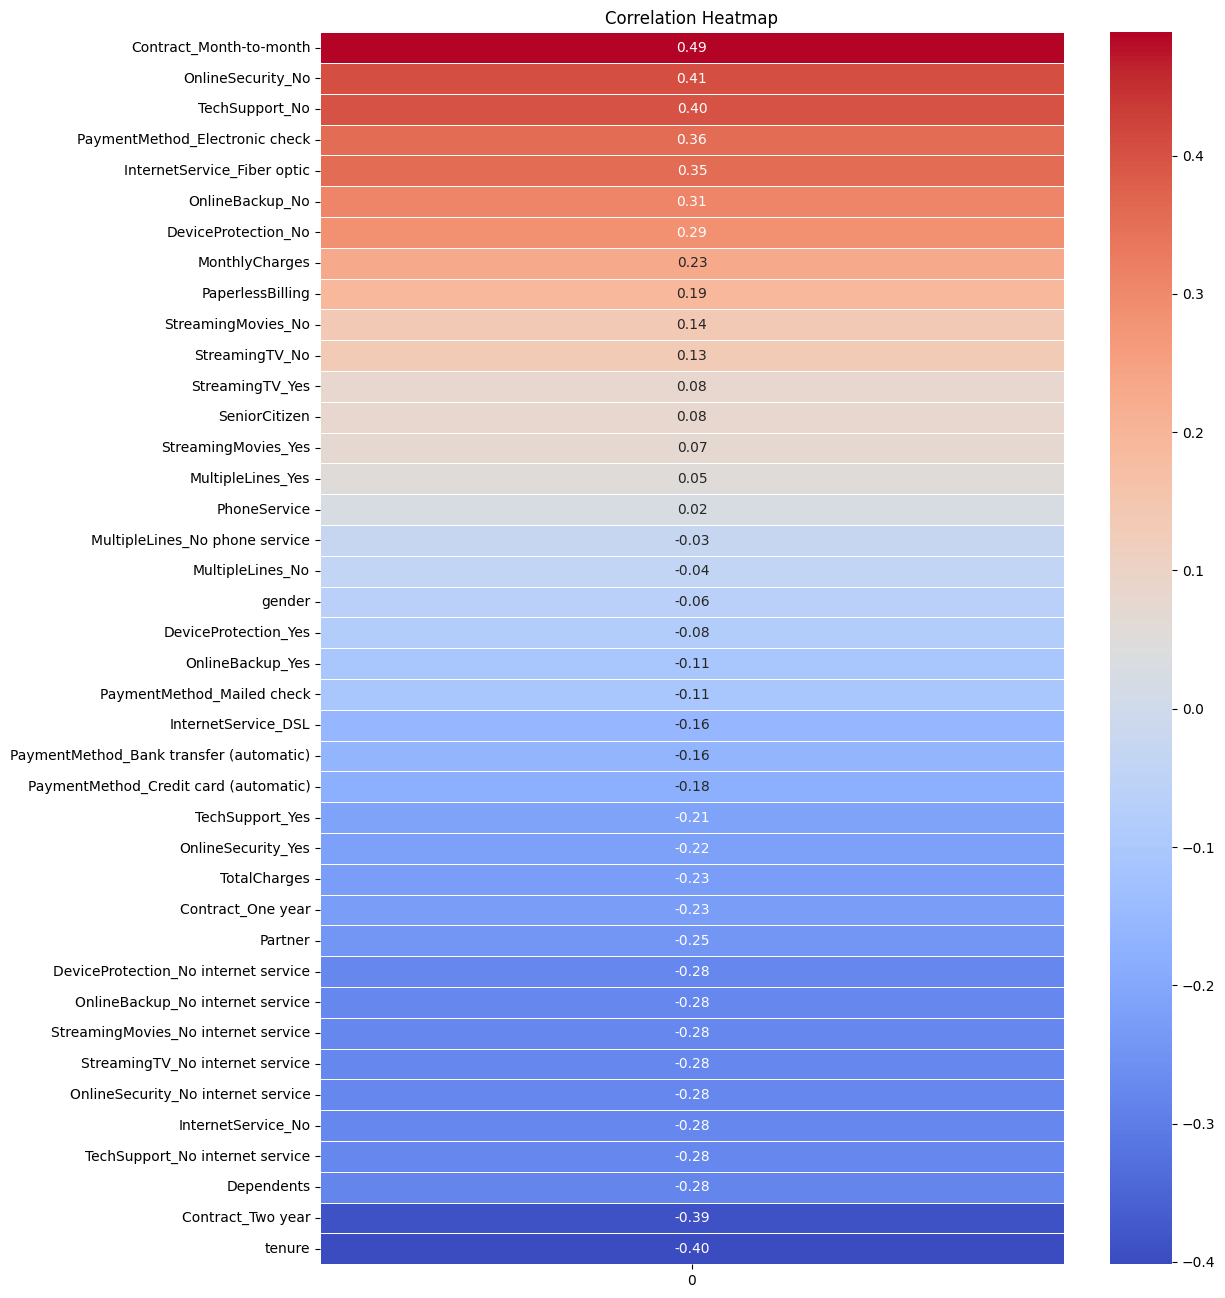

In [121]:
plt.figure(figsize=(12,16))
corr=X_train_balance.corrwith(y_train_balance).sort_values(ascending=False).to_frame()
plt.figure(figsize=(12,16))
sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

Feature selection

In [105]:
selected_col=['Contract_Month-to-month','Contract_Two year','DeviceProtection_No']

X_train_selected_col=X_train_balance[selected_col]
X_test_selected_col=X_test_final[selected_col]

In [106]:
X_test_selected_col

,Contract_Month-to-month,Contract_Two year,DeviceProtection_No
437,0.0,1.0,0.0
2280,1.0,0.0,1.0
2235,0.0,0.0,0.0
4460,1.0,0.0,0.0
3761,0.0,1.0,0.0
...,...,...,...
5143,0.0,0.0,0.0
4439,0.0,1.0,0.0
3857,1.0,0.0,0.0
4758,0.0,1.0,0.0


In [107]:
print("X shape:", X_train_selected_col.shape)
print("y shape:", y_train_balance.shape)

X shape: (8278, 3)
y shape: (8278,)


##LogisticRegression

In [108]:
lr=LogisticRegression()

lr.fit(X_train_selected_col,y_train_balance)

LogisticRegression()

Prediction

In [109]:
lr_train_pred=lr.predict(X_train_selected_col)
lr_test_pred=lr.predict(X_test_selected_col)

In [125]:
print(lr_test_pred)

[0 1 0 ... 1 0 0]


###LogisticRegression Accuracy Score

In [110]:
lr_train_acc=accuracy_score(y_train_balance,lr_train_pred)
lr_test_acc=accuracy_score(y_test,lr_test_pred)

print('train accuracy_score:',lr_train_acc)
print('test accuracy_score:',lr_test_acc)

train accuracy_score: 0.7287992268663929
test accuracy_score: 0.6529453513129879


###LogisticRegression Confusion matrix

confusion matrix
[[591 444]
 [ 45 329]]


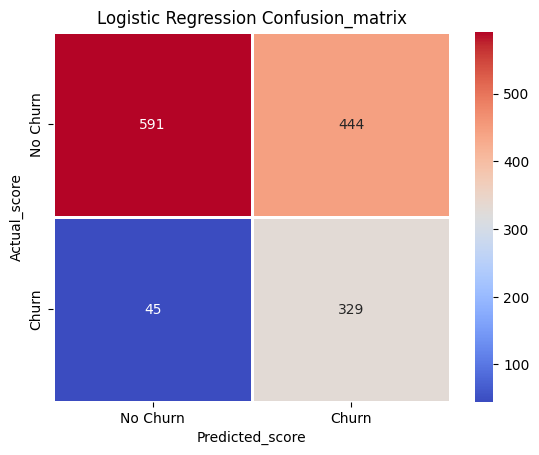

In [111]:
lr_cm=confusion_matrix(y_test,lr_test_pred)
print('confusion matrix')
print(lr_cm)

sns.heatmap(lr_cm,annot=True,fmt='d',cmap='coolwarm',linewidths=1,xticklabels=['No Churn', 'Churn'],yticklabels=['No Churn', 'Churn'])
plt.title('Logistic Regression Confusion_matrix')
plt.xlabel('Predicted_score')
plt.ylabel('Actual_score')
plt.show()

###LogisticRegression Classififcation report

In [112]:
lr_cr=classification_report(y_test,lr_test_pred)

print('Classification report')
print(lr_cr)

Classification report
              precision    recall  f1-score   support

           0       0.93      0.57      0.71      1035
           1       0.43      0.88      0.57       374

    accuracy                           0.65      1409
   macro avg       0.68      0.73      0.64      1409
weighted avg       0.80      0.65      0.67      1409



###Predict_Proab

In [132]:
lr_train_proba=lr.predict_proba(X_train_selected_col)
lr_test_proba=lr.predict_proba(X_test_selected_col)[:, 1]

In [126]:
print(lr_test_proba)

[[0.93150908 0.06849092]
 [0.28683551 0.71316449]
 [0.78224435 0.21775565]
 ...
 [0.39320919 0.60679081]
 [0.93150908 0.06849092]
 [0.93150908 0.06849092]]


In [133]:
thresholds=[0.3,0.5,0.7]
result=[]

for threshold in thresholds:
  pred=(lr_test_proba>=threshold).astype(int)

  result.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(result)

print(threshold_results)

   Threshold  Accuracy  Precision    Recall  F1 Score
0        0.3  0.611781   0.400460  0.930481  0.559936
1        0.5  0.652945   0.425614  0.879679  0.573670
2        0.7  0.711143   0.465979  0.604278  0.526193


##KNeighborsClassifier

In [113]:
knn=KNeighborsClassifier(n_neighbors=4)

knn.fit(X_train_selected_col,y_train_balance)

KNeighborsClassifier(n_neighbors=4)

Prediction

In [114]:
knn_train_pred=knn.predict(X_train_selected_col)
knn_test_pred=knn.predict(X_test_selected_col)

In [115]:
pd.Series(knn_test_pred).value_counts()

,count
0,1409


##Knn Accuracy score

In [116]:
knn_train_acc=accuracy_score(y_train_balance,knn_train_pred)
knn_test_acc=accuracy_score(y_test,knn_test_pred)

print('knn train accuracy:',knn_train_acc)
print('knn test accuracy:',knn_test_acc)

knn train accuracy: 0.5311669485382943
knn test accuracy: 0.7345635202271115


##Knn Confusion matrix

knn confusion matrix:
[[1035    0]
 [ 374    0]]


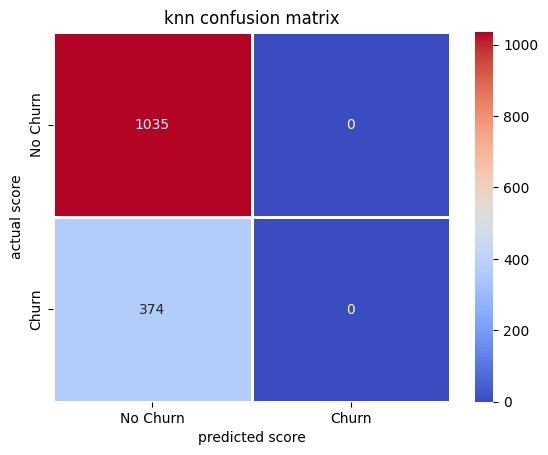

In [117]:
knn_cm=confusion_matrix(y_test,knn_test_pred)

print('knn confusion matrix:')
print(knn_cm)
sns.heatmap(knn_cm,annot=True,fmt='d',cmap='coolwarm',linewidths=1,xticklabels=['No Churn', 'Churn'],yticklabels=['No Churn', 'Churn'])
plt.title('knn confusion matrix')
plt.xlabel('predicted score')
plt.ylabel('actual score')
plt.show()

##Knn Classiffication report

In [118]:
knn_cr=classification_report(y_test,knn_test_pred)
print('knn Classification report')
print(knn_cr)

knn Classification report
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [119]:
from sklearn.metrics import precision_score, recall_score, f1_score
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN'],

    'Accuracy': [
        accuracy_score(y_test, lr_test_pred),
        accuracy_score(y_test, knn_test_pred)
    ],

    'Precision': [
        precision_score(y_test, lr_test_pred),
        precision_score(y_test, knn_test_pred)
    ],

    'Recall': [
        recall_score(y_test, lr_test_pred),
        recall_score(y_test, knn_test_pred)
    ],

    'F1 Score': [
        f1_score(y_test, lr_test_pred),
        f1_score(y_test, knn_test_pred)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.652945   0.425614  0.879679   0.57367
1                  KNN  0.734564   0.000000  0.000000   0.00000


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Prediction Proba

In [143]:
knn_train_proba=knn.predict_proba(X_train_selected_col)
knn_test_proba=knn.predict_proba(X_test_selected_col)[:,1]

In [144]:
thresholds=[0.3,0.5,0.7]
result=[]

for threshold in thresholds:
  pred=(knn_test_proba>=threshold).astype(int)

  result.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(result)

print(threshold_results)

   Threshold  Accuracy  Precision  Recall  F1 Score
0        0.3  0.734564        0.0     0.0       0.0
1        0.5  0.734564        0.0     0.0       0.0
2        0.7  0.734564        0.0     0.0       0.0


Logistic Regression performed better in identifying churn customers. Threshold 0.5 achieved the highest F1-score (57.37%) among the three tested thresholds.

KNN achieved 73.46% accuracy, but precision, recall and F1-score were all zero at every tested threshold.

Logistic Regression is better than KNN for this churn prediction task because it successfully identifies churn customers, whereas KNN fails to detect any churn cases.